# 02 · House prices: Land Registry Price Paid data

Residential sales since 2018 in the comparison districts (SE16, SE8, E14, E1W),
from the HM Land Registry Price Paid API, geocoded to postcode centroids via
postcodes.io, with before/after access times from notebook 01 attached.

Only "standard" (category A) sales are kept, which drops repossessions,
buy-to-let portfolio and non-market transfers. Property types kept: detached,
semi, terraced, flat.

Contains HM Land Registry data © Crown copyright and database right 2026,
licensed under the Open Government Licence v3.0.


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import requests

from common import DERIVED, DISTRICTS, FIGURES, RAW, SALES_FROM, WGS84, attach_access

PPD_URL = "https://landregistry.data.gov.uk/app/ppd/ppd_data.csv"

In [ ]:
def fetch_district(district: str) -> pd.DataFrame:
    path = RAW / f"ppd_{district}_{SALES_FROM}.csv"
    if not path.exists():
        r = requests.get(
            PPD_URL,
            params={"header": "true", "limit": "all", "postcode": district, "min_date": SALES_FROM},
            timeout=600,
        )
        r.raise_for_status()
        path.write_bytes(r.content)
    return pd.read_csv(path, dtype=str)


sales = pd.concat([fetch_district(d) for d in DISTRICTS], ignore_index=True)
# The API matches on postcode prefix, so "SE1" style overlaps are possible; keep exact districts.
sales["district"] = sales["postcode"].str.split().str[0]
sales = sales[sales["district"].isin(DISTRICTS)]
sales = sales[(sales["transaction_category"] == "A") & sales["property_type"].isin(list("DSTF"))]
sales["price"] = sales["price_paid"].astype(int)
sales["date"] = pd.to_datetime(sales["deed_date"])
sales["year"] = sales["date"].dt.year
sales = sales.drop_duplicates("unique_id")
print(f"{len(sales):,} standard residential sales since {SALES_FROM}")
sales.groupby(["district", "property_type"]).price.agg(["size", "median"]).unstack()

20,929 standard residential sales since 2018-01-01


size                     median                              
property_type    D      F   S    T          D         F         S         T
district                                                                   
E14              3  11934  44  525  1200000.0  525000.0  792500.0  687000.0
E1W              5   1969   3  104  1125000.0  686226.0  900000.0  872475.0
SE16             9   3376  66  534   645000.0  450000.0  722500.0  705000.0
SE8              4   2006  20  327   793500.0  400000.0  720000.0  637500.0

## Geocode postcodes (postcodes.io, cached)


In [ ]:
def geocode(postcodes: list[str]) -> pd.DataFrame:
    path = RAW / "postcodes.csv"
    cached = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=["postcode", "lon", "lat"])
    todo = sorted(set(postcodes) - set(cached["postcode"]))
    rows = []
    for i in range(0, len(todo), 100):
        r = requests.post("https://api.postcodes.io/postcodes", json={"postcodes": todo[i : i + 100]}, timeout=60)
        r.raise_for_status()
        for item in r.json()["result"]:
            res = item["result"]
            rows.append(
                {
                    "postcode": item["query"],
                    "lon": res["longitude"] if res else None,
                    "lat": res["latitude"] if res else None,
                }
            )
    if rows:
        cached = pd.concat([cached, pd.DataFrame(rows)], ignore_index=True)
        cached.to_csv(path, index=False)
    return cached


pcs = geocode(sales["postcode"].dropna().unique().tolist())
sales = sales.merge(pcs, on="postcode", how="left")
print(f"Geocoded {sales.lon.notna().mean():.1%} of sales (terminated postcodes are the usual gap)")
sales = sales.dropna(subset=["lon"])

Geocoded 100.0% of sales (terminated postcodes are the usual gap)


## Attach access times


In [ ]:
gsales = gpd.GeoDataFrame(sales, geometry=gpd.points_from_xy(sales.lon, sales.lat), crs=WGS84)
gsales = attach_access(gsales)
keep = [
    "unique_id",
    "price",
    "date",
    "year",
    "postcode",
    "district",
    "property_type",
    "new_build",
    "estate_type",
    "saon",
    "paon",
    "street",
    "lon",
    "lat",
    "walk_before",
    "walk_after",
    "pt_before",
    "pt_after",
    "access_before",
    "access_after",
    "cycle_before",
    "cycle_after",
    "geometry",
]
gsales = gsales[keep]
gsales.to_file(DERIVED / "sales.gpkg", driver="GPKG")
gsales.drop(columns="geometry").to_csv(DERIVED / "sales.csv", index=False)
print(f"{len(gsales):,} sales saved")

20,926 sales saved


## First look: price vs access time


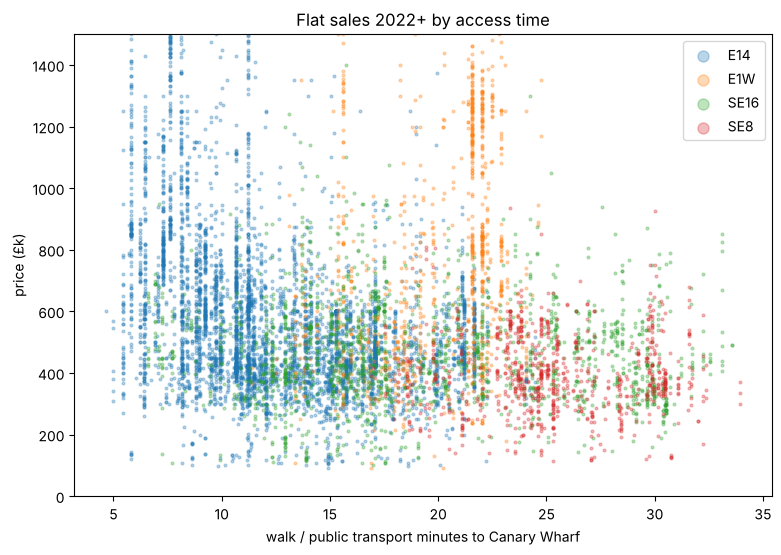

In [ ]:
flats = gsales[(gsales.property_type == "F") & (gsales.year >= 2022)]
fig, ax = plt.subplots(figsize=(9, 6))
for d, grp in flats.groupby("district"):
    ax.scatter(grp.access_before, grp.price / 1e3, s=4, alpha=0.3, label=d)
ax.set(
    xlabel="walk / public transport minutes to Canary Wharf",
    ylabel="price (£k)",
    title="Flat sales 2022+ by access time",
    ylim=(0, 1500),
)
ax.legend(markerscale=4)
fig.savefig(FIGURES / "02_price_vs_access.png", dpi=150, bbox_inches="tight")